# 04 · EMT-TF Expression (unconditional)
Categorical overlay of thresholded EMT-TF expressers on a grey manifold (NOT a continuous single-gene colormap). Panel widened beyond Snail/Zeb/Twist to include the FOXC and PRRX families; VIM is a mesenchymal marker, not a TF, and is excluded. Gate each TF on detectable expression; show the root-end and terminus-end factors.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load signatures; use house linear layout

In [4]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 360 | pseudotime range 0.0 -> 6.8


### EMT-TF panel — detection + pseudotime association
Score each TF by expressed fraction and mean early(root)/late(terminus) expression + Spearman vs pseudotime. Keep detectable TFs (frac_expr > 0.03); derive an early/root and late/terminus factor.

In [6]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
print('\nexpressed (frac>0.03):', list(ok.TF))
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'derived pair: {early_tf} (early/root=pSom origin) <-> {late_tf} (late/terminus=Crest)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t         end
 FOXC1      0.333       1.598      0.633    -0.266 EARLY(root)
 SNAI2      0.075       0.605      0.012    -0.254 EARLY(root)
  ZEB2      0.050       0.223      0.008    -0.204 EARLY(root)
 PRRX1      0.056       0.242      0.084    -0.160 EARLY(root)
  ZEB1      0.039       0.171      0.056    -0.148 EARLY(root)
TWIST1      0.036       0.123      0.026    -0.123 EARLY(root)
TWIST2      0.011       0.076      0.000    -0.107 EARLY(root)
 SNAI1      0.044       0.201      0.163    -0.104 EARLY(root)
 PRRX2      0.011       0.052      0.029    -0.078 EARLY(root)

expressed (frac>0.03): ['FOXC1', 'SNAI2', 'ZEB2', 'PRRX1', 'ZEB1', 'TWIST1', 'SNAI1']
derived pair: FOXC1 (early/root=pSom origin) <-> SNAI1 (late/terminus=Crest)


### Deliverable — `expression.pdf`
Categorical overlay: grey manifold, thresholded expressers of the two derived TFs in colour. Display cutoff = upper quartile among expressing cells.

overlay thresholds (upper quartile among expressers): {'FOXC1': 4.269, 'SNAI1': 4.272} | cells shown: {'FOXC1': 30, 'SNAI1': 4}
FOXC1: 33.3% expressing; 30 shown (upper quartile), mean pseudotime of shown cells = 0.45 (all cells = 0.52)
SNAI1: 4.4% expressing; 4 shown (upper quartile), mean pseudotime of shown cells = 0.83 (all cells = 0.52)
saved expression.pdf


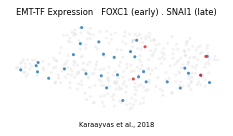

In [8]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) . {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Karaayvas et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
print('saved expression.pdf')